# Ponderación por clase

## 1. Entorno y configuración del experimento

In [1]:
from pathlib import Path
from textwrap import fill
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "cfpb_complaints_2023-06-01_2024-05-31").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encuentra el corte CFPB en su carpeta original.")
for folder in [ROOT / "Baseline", ROOT / "Modelado"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from baseline import cargar_datos, crear_particiones, auditar_particiones
from ponderacion import comparar_ponderacion, BASE, WEIGHTED
plt.rcParams.update({"figure.dpi":110, "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False})
display(pd.Series({
    "Objetivo": "Comparar None frente a class_weight='balanced'",
    "Variable que cambia": "Solo class_weight; resto de parámetros idéntico",
    "Muestra": "Las mismas filas de entrenamiento, sin duplicar ni eliminar ejemplos",
    "Pesos": "n_train / (11 × frecuencia de cada clase en entrenamiento)",
    "Vectorización": "Un único TF-IDF ajustado en entrenamiento, compartido por los dos modelos",
    "Particiones": "Las mismas 70/15/15 estratificadas por Product, semilla 42",
    "Selección": "Solo validación; prueba no se transforma ni se evalúa en este experimento",
    "Referencia": "Se reproduce el ajuste sin pesos en este notebook, sin sobrescribir el baseline",
    "Criterio principal": "Macro-F1; acompañar con precisión, recall, F1 y soporte por clase",
    "Salida": "Tablas y gráficas en este notebook, sin archivos de resultados externos",
}, name="Configuración").to_frame())

,Configuración
Objetivo,Comparar None frente a class_weight='balanced'
Variable que cambia,Solo class_weight; resto de parámetros idéntico
Muestra,"Las mismas filas de entrenamiento, sin duplica..."
Pesos,n_train / (11 × frecuencia de cada clase en en...
Vectorización,"Un único TF-IDF ajustado en entrenamiento, com..."
Particiones,Las mismas 70/15/15 estratificadas por Product...
Selección,Solo validación; prueba no se transforma ni se...
Referencia,Se reproduce el ajuste sin pesos en este noteb...
Criterio principal,"Macro-F1; acompañar con precisión, recall, F1 ..."
Salida,"Tablas y gráficas en este notebook, sin archiv..."


## 2. Datos y particiones compartidas con el baseline

In [ ]:
datos = cargar_datos(ROOT)
particiones = crear_particiones(datos)
auditoria = auditar_particiones(datos, particiones)
display(auditoria["resumen"].round(2))
display(auditoria["soporte"])

,Filas,% del corte,Clases,Textos distintos,Fecha mínima,Fecha máxima
Partición,,,,,,
Entrenamiento,407741,70.0,11,266428,2023-06-01,2024-05-31
Validación,87374,15.0,11,64464,2023-06-01,2024-05-31
Prueba,87374,15.0,11,64387,2023-06-01,2024-05-31


,Entrenamiento,Validación,Prueba
Product,,,
Credit reporting or other personal consumer reports,294854,63184,63184
Debt collection,34807,7459,7459
Credit card,26609,5702,5702
Checking or savings account,19070,4087,4086
Mortgage,8444,1810,1810
"Money transfer, virtual currency, or money service",6324,1355,1355
Student loan,5925,1269,1270
Vehicle loan or lease,5053,1083,1083
"Payday loan, title loan, personal loan, or advance loan",3279,702,702


,SHA-256 de IDs de cada partición
Entrenamiento,5f8878b5bfa22a4f87f2ecc5aa0d1e7b964522a15b309e...
Validación,6c517834a870868a4238437e01588ff3ba2342215a68dc...
Prueba,00516400ee045527cc47e70ad3ae95549511f943a87738...


## 3. Entrenamiento y pesos de clase

In [3]:
experimento = comparar_ponderacion(datos, particiones)
display(experimento["pesos"].round(4))
display(experimento["ajustes"].round(2))
display(pd.Series({
    "Tiempo vectorización común (s)": round(experimento["vectorizacion_segundos"],2),
    "Vocabulario compartido": experimento["vocabulario"],
    "Filas de entrenamiento en ambos modelos": experimento["filas_entrenamiento"],
    "Filas de validación en ambos modelos": experimento["filas_validacion"],
    "Conjunto de prueba evaluado": experimento["prueba_evaluada"],
}, name="Control del experimento").to_frame())

,Filas en entrenamiento,Peso,Peso total de la clase
Product,,,
Checking or savings account,19070,1.9438,37067.3636
Credit card,26609,1.3930,37067.3636
Credit reporting or other personal consumer reports,294854,0.1257,37067.3636
Debt collection,34807,1.0649,37067.3636
Debt or credit management,805,46.0464,37067.3636
"Money transfer, virtual currency, or money service",6324,5.8614,37067.3636
Mortgage,8444,4.3898,37067.3636
"Payday loan, title loan, personal loan, or advance loan",3279,11.3045,37067.3636
Prepaid card,2571,14.4175,37067.3636


,Modelo,Ajuste clasificador (s),Iteraciones,Avisos
0,Sin ponderación,125.41,55,Sin avisos
1,Ponderación por clase,149.12,72,Sin avisos


,Control del experimento
Tiempo vectorización común (s),137.62
Vocabulario compartido,80000
Filas de entrenamiento en ambos modelos,407741
Filas de validación en ambos modelos,87374
Conjunto de prueba evaluado,False


## 4. Comparación global en validación

,Accuracy,Macro-F1,F1 ponderada
Modelo,,,
Sin ponderación,0.9012,0.6691,0.8966
Ponderación por clase,0.8488,0.6619,0.8621


,Cambio absoluto
Accuracy,-0.0524
Macro-F1,-0.0072
F1 ponderada,-0.0345


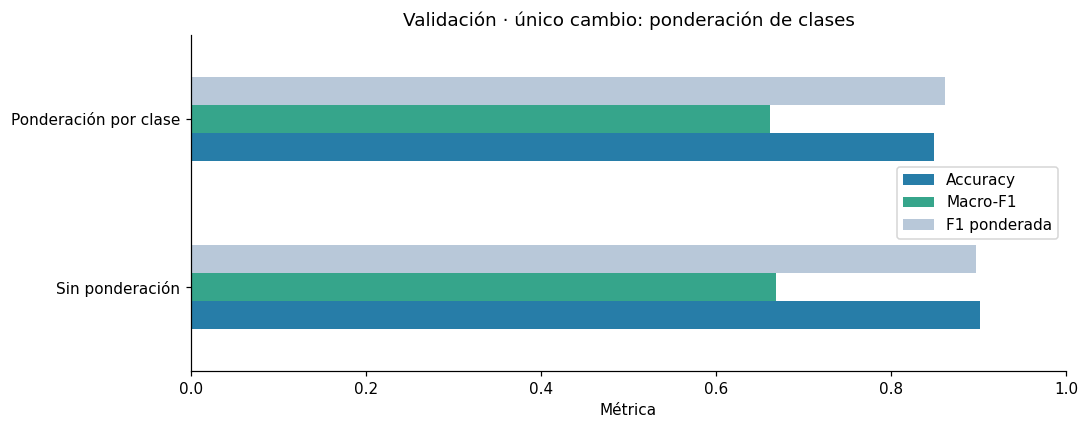

In [ ]:
display(experimento["metricas"].round(4))
display(experimento["cambios_globales"].round(4).to_frame())

## 5. Efecto en cada categoría

,precision · Sin ponderación,recall · Sin ponderación,f1-score · Sin ponderación,precision · Ponderación por clase,recall · Ponderación por clase,f1-score · Ponderación por clase,Soporte validación,Cambio precision,Cambio recall,Cambio f1-score
Product,,,,,,,,,,
Checking or savings account,0.7594,0.8385,0.7970,0.7812,0.8055,0.7932,4087,0.0218,-0.0330,-0.0038
Credit card,0.7807,0.7797,0.7802,0.6795,0.8204,0.7434,5702,-0.1011,0.0407,-0.0368
Credit reporting or other personal consumer reports,0.9394,0.9707,0.9548,0.9844,0.8600,0.9180,63184,0.0450,-0.1107,-0.0368
Debt collection,0.7917,0.6710,0.7264,0.5808,0.8214,0.6805,7459,-0.2109,0.1504,-0.0459
Debt or credit management,0.0000,0.0000,0.0000,0.0780,0.3256,0.1258,172,0.0780,0.3256,0.1258
"Money transfer, virtual currency, or money service",0.7488,0.5919,0.6612,0.6194,0.7675,0.6856,1355,-0.1294,0.1756,0.0244
Mortgage,0.8610,0.8591,0.8601,0.7679,0.9232,0.8384,1810,-0.0931,0.0641,-0.0216
"Payday loan, title loan, personal loan, or advance loan",0.6582,0.2963,0.4086,0.3433,0.7009,0.4609,702,-0.3149,0.4046,0.0522
Prepaid card,0.9361,0.5318,0.6782,0.6435,0.7895,0.7090,551,-0.2926,0.2577,0.0308


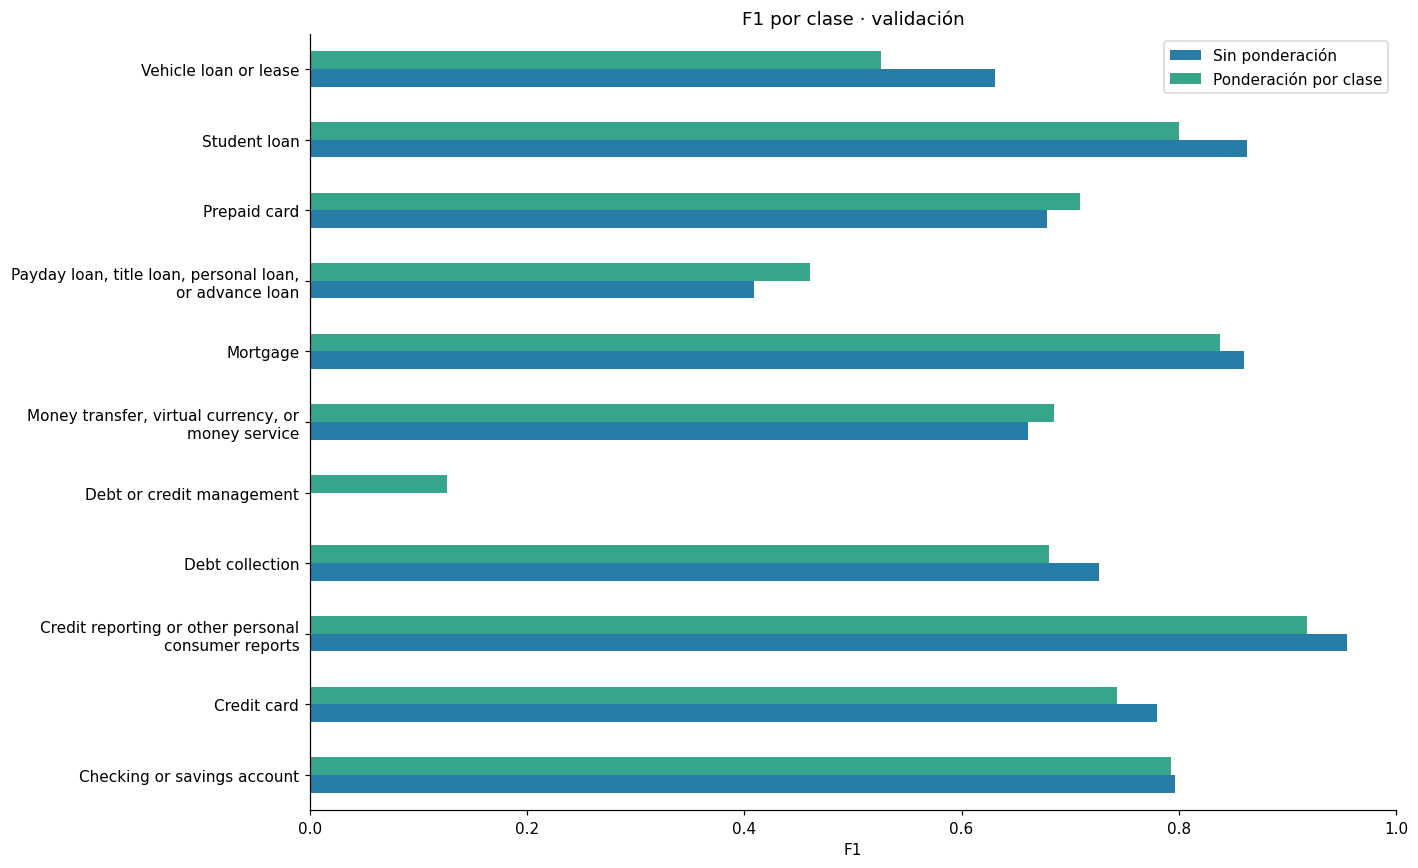

In [5]:
display(experimento["clases"].round(4))
f1_comparison = pd.DataFrame({name: experimento["reportes"][name]["f1-score"] for name in [BASE, WEIGHTED]})
f1_comparison.index = [fill(label,40) for label in f1_comparison.index]
fig, ax = plt.subplots(figsize=(13,8))
f1_comparison.plot.barh(ax=ax, color=["#277da8", "#36a58b"])
ax.set(title="F1 por clase · validación", xlabel="F1", ylabel="", xlim=(0,1))
plt.tight_layout(); plt.show()

## 6. Resultados por empresa y exposición previa del texto

In [ ]:
# Macro-F1 usa las mismas 11 etiquetas en todos los subgrupos; se muestra su soporte.
display(experimento["empresas"].round(4))

,Empresa / grupo,Modelo,Filas,Clases presentes,Accuracy,Macro-F1,F1 ponderada
0,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Sin ponderación,20842,8,0.9658,0.2519,0.9657
1,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",Ponderación por clase,20842,8,0.8981,0.2149,0.9207
2,"EQUIFAX, INC.",Sin ponderación,20305,8,0.9701,0.2884,0.9704
3,"EQUIFAX, INC.",Ponderación por clase,20305,8,0.9088,0.2312,0.9301
4,Experian Information Solutions Inc.,Sin ponderación,19599,7,0.9663,0.2749,0.9671
5,Experian Information Solutions Inc.,Ponderación por clase,19599,7,0.8891,0.2118,0.9168
6,Resto de empresas,Sin ponderación,26628,11,0.7503,0.6542,0.7451
7,Resto de empresas,Ponderación por clase,26628,11,0.7348,0.6805,0.7329


,Texto visto en entrenamiento,Modelo,Filas,Clases presentes,Accuracy,Macro-F1,F1 ponderada
0,True,Sin ponderación,36779,11,0.9644,0.4613,0.9649
1,True,Ponderación por clase,36779,11,0.9064,0.3156,0.9246
2,False,Sin ponderación,50595,11,0.8553,0.6657,0.8481
3,False,Ponderación por clase,50595,11,0.8069,0.6747,0.8190


## 7. Matriz de confusión del modelo ponderado

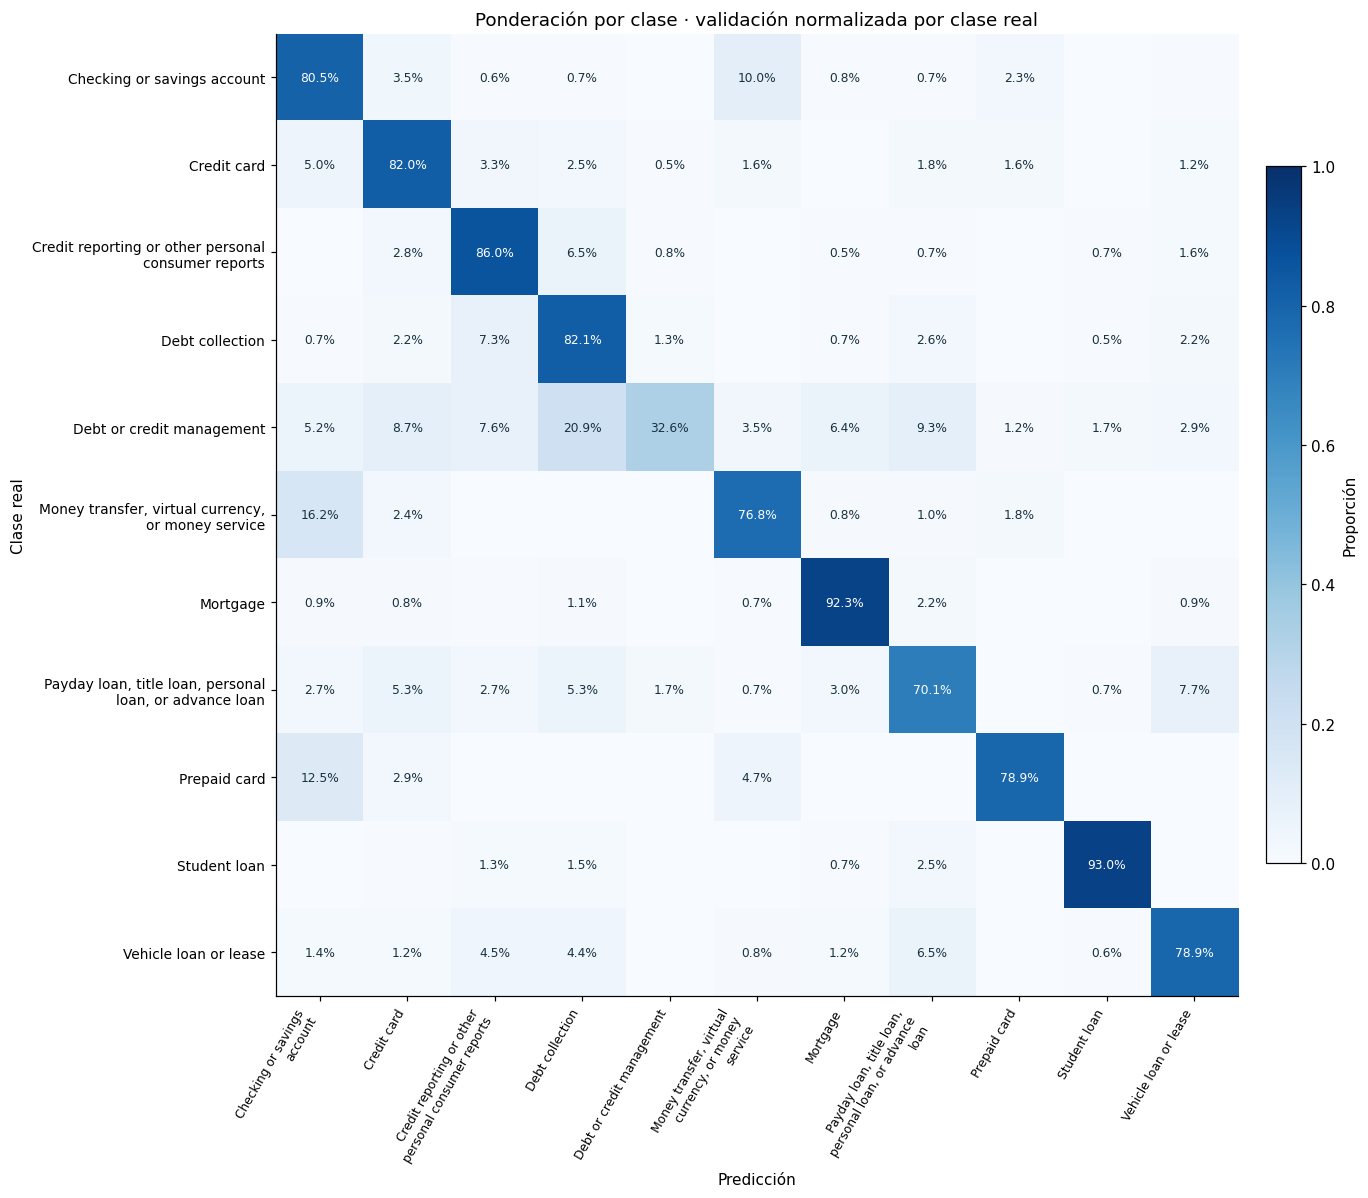

In [7]:
labels = experimento["labels"]
matrix = experimento["matrices"][WEIGHTED]
fig, ax = plt.subplots(figsize=(14,11))
image = ax.imshow(matrix, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(labels)), [fill(p,25) for p in labels], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), [fill(p,35) for p in labels], fontsize=9)
for row in range(len(labels)):
    for col in range(len(labels)):
        if matrix[row,col]>=.005:
            ax.text(col,row,f"{matrix[row,col]:.1%}",ha="center",va="center",fontsize=8,
                    color="white" if matrix[row,col]>.5 else "#19313f")
ax.set(title="Ponderación por clase · validación normalizada por clase real", xlabel="Predicción", ylabel="Clase real")
fig.colorbar(image, ax=ax, fraction=.025, pad=.02, label="Proporción")
plt.tight_layout(); plt.show()

## 8. Lectura del experimento

In [8]:
delta = experimento["cambios_globales"]
rare = "Debt or credit management"
display(pd.Series({
    "Cambio macro-F1": round(delta["Macro-F1"],4),
    "Cambio accuracy (puntos porcentuales)": round(100*delta["Accuracy"],2),
    "F1 Debt or credit management sin pesos": round(experimento["reportes"][BASE].loc[rare,"f1-score"],4),
    "F1 Debt or credit management con pesos": round(experimento["reportes"][WEIGHTED].loc[rare,"f1-score"],4),
    "Qué cambia": "La influencia de cada clase en el ajuste; no su número de ejemplos",
    "Qué no demuestra": "Mejora en nuevas empresas, otro periodo o datos reales de webs",
    "Limitación de la evaluación": "Se conservan textos compartidos entre entrenamiento y validación",
    "Confianza": "La ponderación no calibra probabilidades; la política de revisión sigue pendiente",
    "Selección final": "Valorar macro-F1, precisión/recall por clase y coste de errores; no solo accuracy",
    "Estado de prueba": "Reservada; no evaluada en este notebook",
}, name="Resumen").to_frame())

,Resumen
Cambio macro-F1,-0.0072
Cambio accuracy (puntos porcentuales),-5.24
F1 Debt or credit management sin pesos,0.0
F1 Debt or credit management con pesos,0.1258
Qué cambia,La influencia de cada clase en el ajuste; no s...
Qué no demuestra,"Mejora en nuevas empresas, otro periodo o dato..."
Limitación de la evaluación,Se conservan textos compartidos entre entrenam...
Confianza,La ponderación no calibra probabilidades; la p...
Selección final,"Valorar macro-F1, precisión/recall por clase y..."
Estado de prueba,Reservada; no evaluada en este notebook
